# Original Transolver — same-case step-flow comparison

FlowMLLab · Ehsan Roohi · g011, Re = 25 / 50 / 100

This notebook reads **actual trained checkpoints and predictions** for the original
Transolver. It is distinct from GeoTransolver in the double-step family study.
The exact historical split is 106 training, 21 validation and three test cases.
All fields are from the existing OpenFOAM archive, not the rarefied DSMC archive.

Three new Transolver seeds are compared with the retained seed-17 Geo-DeepONet,
FNO and U-FNO fields. All plots use seed 17 fixed in advance. Different losses,
training point exposures and hardware prevent a controlled architecture ranking.

Run in a full repository checkout with `pip install -e '.[transolver,test]'`
and `pip install ipykernel`. Training is optional: checkpoints, scalers and raw arrays are included with explicit author authorization.
See [full results and protocol](../../results/step_transolver/README.md).

The default CPU route reads retained results. Current checks of the displayed arrays are separate from the historical checkpoint-replay receipt.

In [1]:
# Late-course checkout setup
from pathlib import Path
import sys, os, subprocess, importlib.util
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                   if (p / 'results/step_transolver/comparison.csv').exists()), None)
try:
    _in_colab = importlib.util.find_spec("google.colab") is not None
except (ModuleNotFoundError, ValueError):
    _in_colab = False
if _in_colab:
    _course_target = ROOT if ROOT is not None else Path("/content/FlowMLLab")
    if not _course_target.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--filter=blob:none",
                        "--sparse", "https://github.com/Ehsan-Roohi/FlowMLLab.git",
                        str(_course_target)], check=True)
    _course_complete = all((_course_target / p).exists() for p in ['results/step_transolver/comparison.csv', 'flowmllab', 'qa', 'notebooks/week15', 'results/step_transolver', 'flowmllab/late_teaching_plots.py'])
    if not _course_complete and (_course_target / ".git").exists():
        _sparse = subprocess.run(["git", "-C", str(_course_target), "config", "--bool",
                                  "core.sparseCheckout"], capture_output=True, text=True, check=False)
        if _sparse.stdout.strip() != "true":
            raise RuntimeError("This full checkout is missing required lesson files; use a complete course checkout or a new Colab runtime.")
        # Add this lesson's dependencies; keep any previous sparse selection.
        subprocess.run(["git", "-C", str(_course_target), "sparse-checkout",
                        "add", *['flowmllab', 'qa', 'notebooks/week15', 'results/step_transolver']], check=True)
    elif not _course_complete:
        raise RuntimeError("The extracted course folder is incomplete for this lesson. Use the complete portable bundle or a new Colab runtime.")
    ROOT = _course_target
if ROOT is None or not all((ROOT / p).exists() for p in ['results/step_transolver/comparison.csv', 'flowmllab', 'qa', 'notebooks/week15', 'results/step_transolver', 'flowmllab/late_teaching_plots.py']):
    raise RuntimeError("Open this notebook in a FlowMLLab checkout, or use its Open in Colab link and run this setup cell first.")
ROOT = ROOT.resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Course checkout:", ROOT)

os.chdir(ROOT)

from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/"results/step_transolver/comparison.csv").exists())
OUT=ROOT/"results/step_transolver"
retained_verification=json.loads((OUT/"verification.json").read_text())
print("Retained replay receipt:",retained_verification["checks"])
print("Default Run All reads retained data; it does not rewrite verification or figure files.")


Course checkout: /scratch3/workspace/roohie_umass_edu-flowml-ghia-highre-20261115/course-late-lectures-20261121/cpu-repo


Retained replay receipt: source/checkpoint hashes, frozen split, exact 9-field inference reproduction
Default Run All reads retained data; it does not rewrite verification or figure files.


## Results and uncertainty

Velocity and centered-pressure errors are relative L2 percentages. Reverse IoU
uses **all fluid cells with u < 0**, not the filtered post-audit metric.
Means and sample standard deviations below concern three Transolver seeds only;
historical models have one retained seed. Checkpoints use validation only, and
all three selected checkpoints are at the 400-epoch budget boundary, so training
saturation is not established.

In [2]:
display(pd.read_csv(OUT/'comparison.csv').round(4))
display(pd.DataFrame(json.loads((OUT/'summary.json').read_text())).round(4))

,Re,model,seed,velocity_percent,pressure_percent,reverse_iou,reverse_area_bias_percent
0,25,Geo-DeepONet,17,29.8898,47.8743,0.3994,5.5872
1,25,FNO,17,17.3778,52.3667,0.6642,0.6637
2,25,U-FNO,17,19.4525,48.4315,0.6582,0.8096
3,25,Transolver,17,23.9910,70.5154,0.3343,-2.0861
4,25,Transolver,29,27.6163,72.2669,0.4674,-1.9183
5,25,Transolver,43,25.3894,71.3493,0.6217,-1.1597
6,50,Geo-DeepONet,17,26.1111,32.3959,0.6030,3.0926
7,50,FNO,17,20.2189,47.4795,0.6388,0.8607
8,50,U-FNO,17,21.5049,72.1918,0.6721,0.7877
9,50,Transolver,17,27.8670,91.0255,0.6035,1.3786


,Re,velocity_percent_mean,velocity_percent_std,pressure_percent_mean,pressure_percent_std,reverse_iou_mean,reverse_iou_std
0,25,25.6655,1.8284,71.3772,0.8761,0.4744,0.1438
1,50,28.6042,0.8872,93.3744,11.4525,0.6407,0.0371
2,100,36.4342,1.5667,73.0785,1.6974,0.5678,0.0861


## Field comparisons

CFD / Geo-DeepONet / FNO / U-FNO / original Transolver. All neural rows show
seed 17, not a test-selected seed. Shared scales, actual per-row streamlines,
physical 5:1 aspect and identical reference fields. Pressure means are removed
independently. Vorticity excludes stencils crossing solid boundaries.

Speed is shown at full width for GitHub readability. Separate pressure and vorticity comparisons are available in the results page.

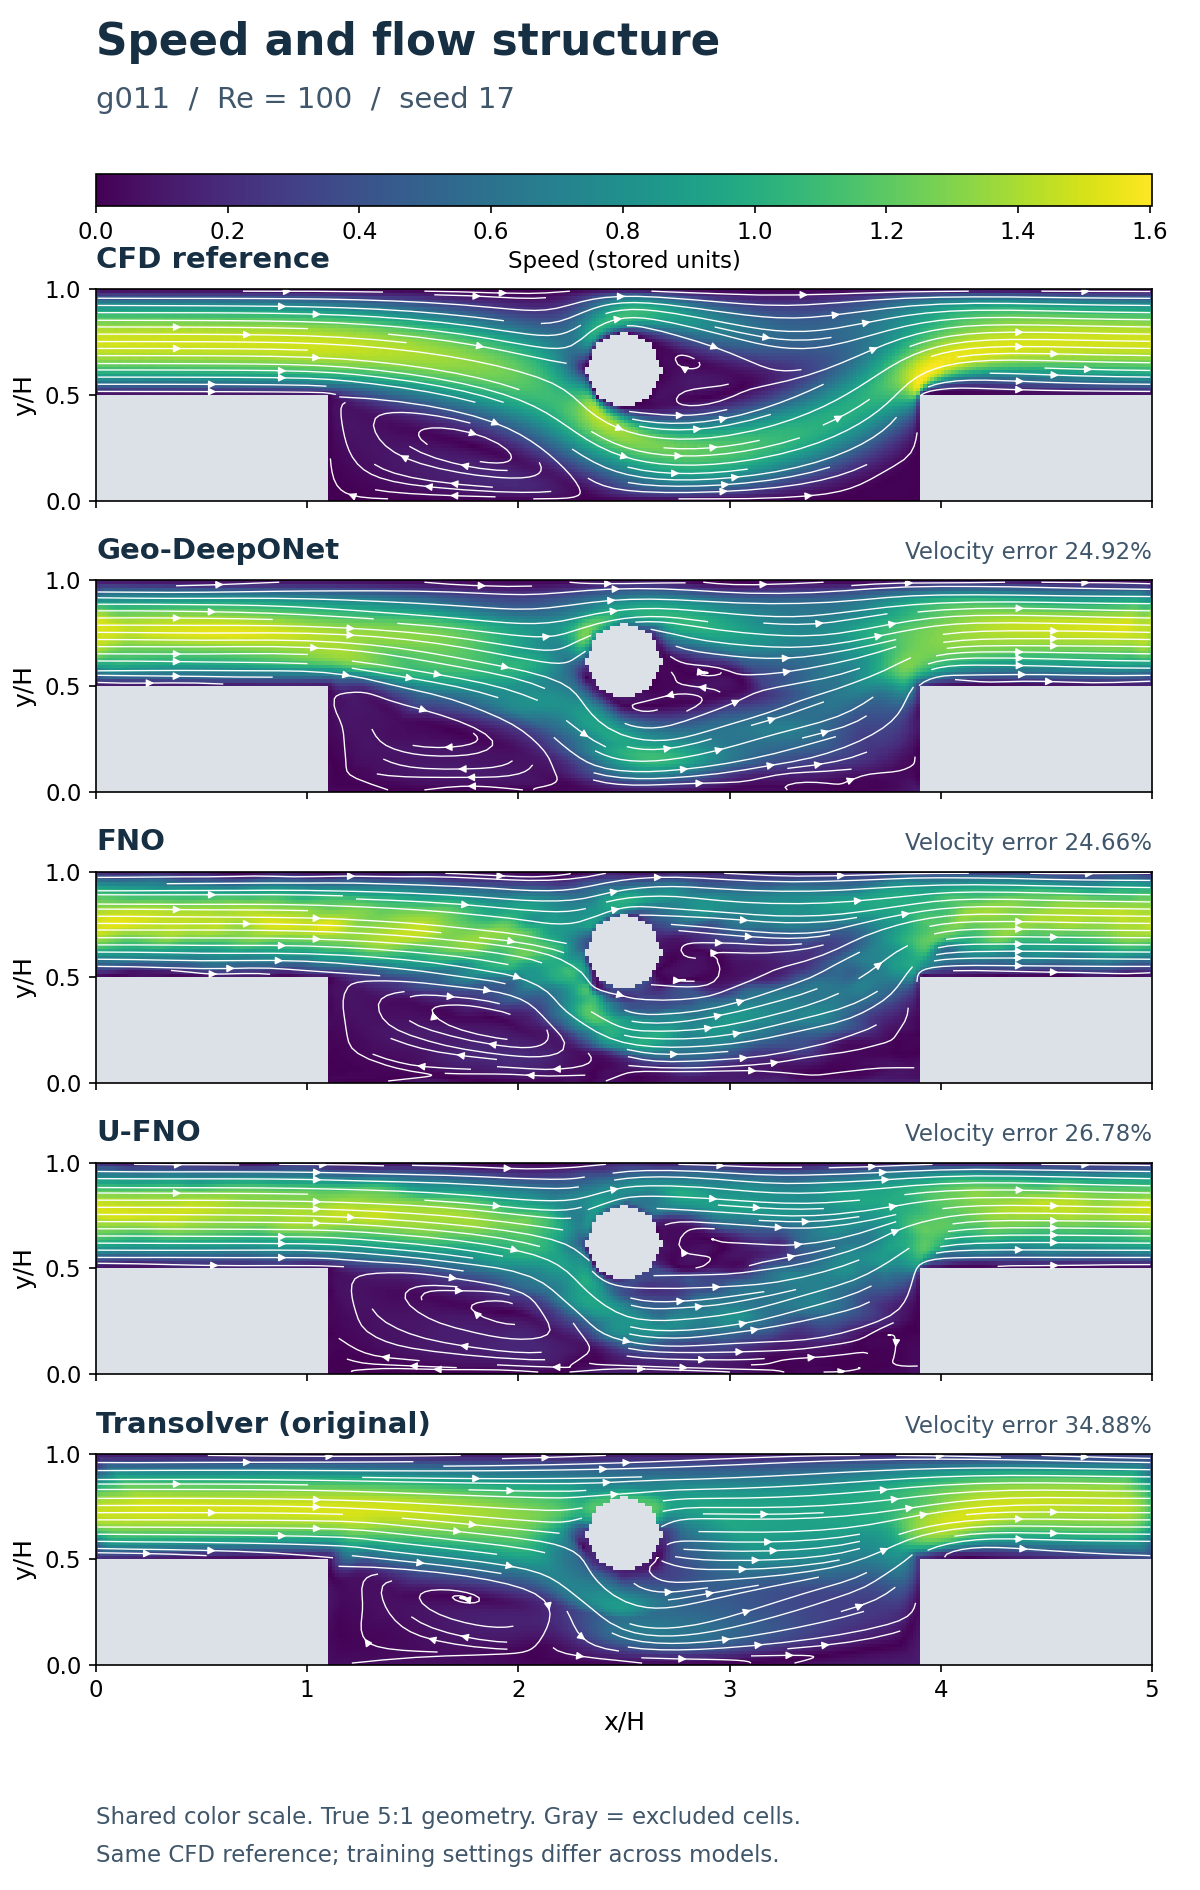

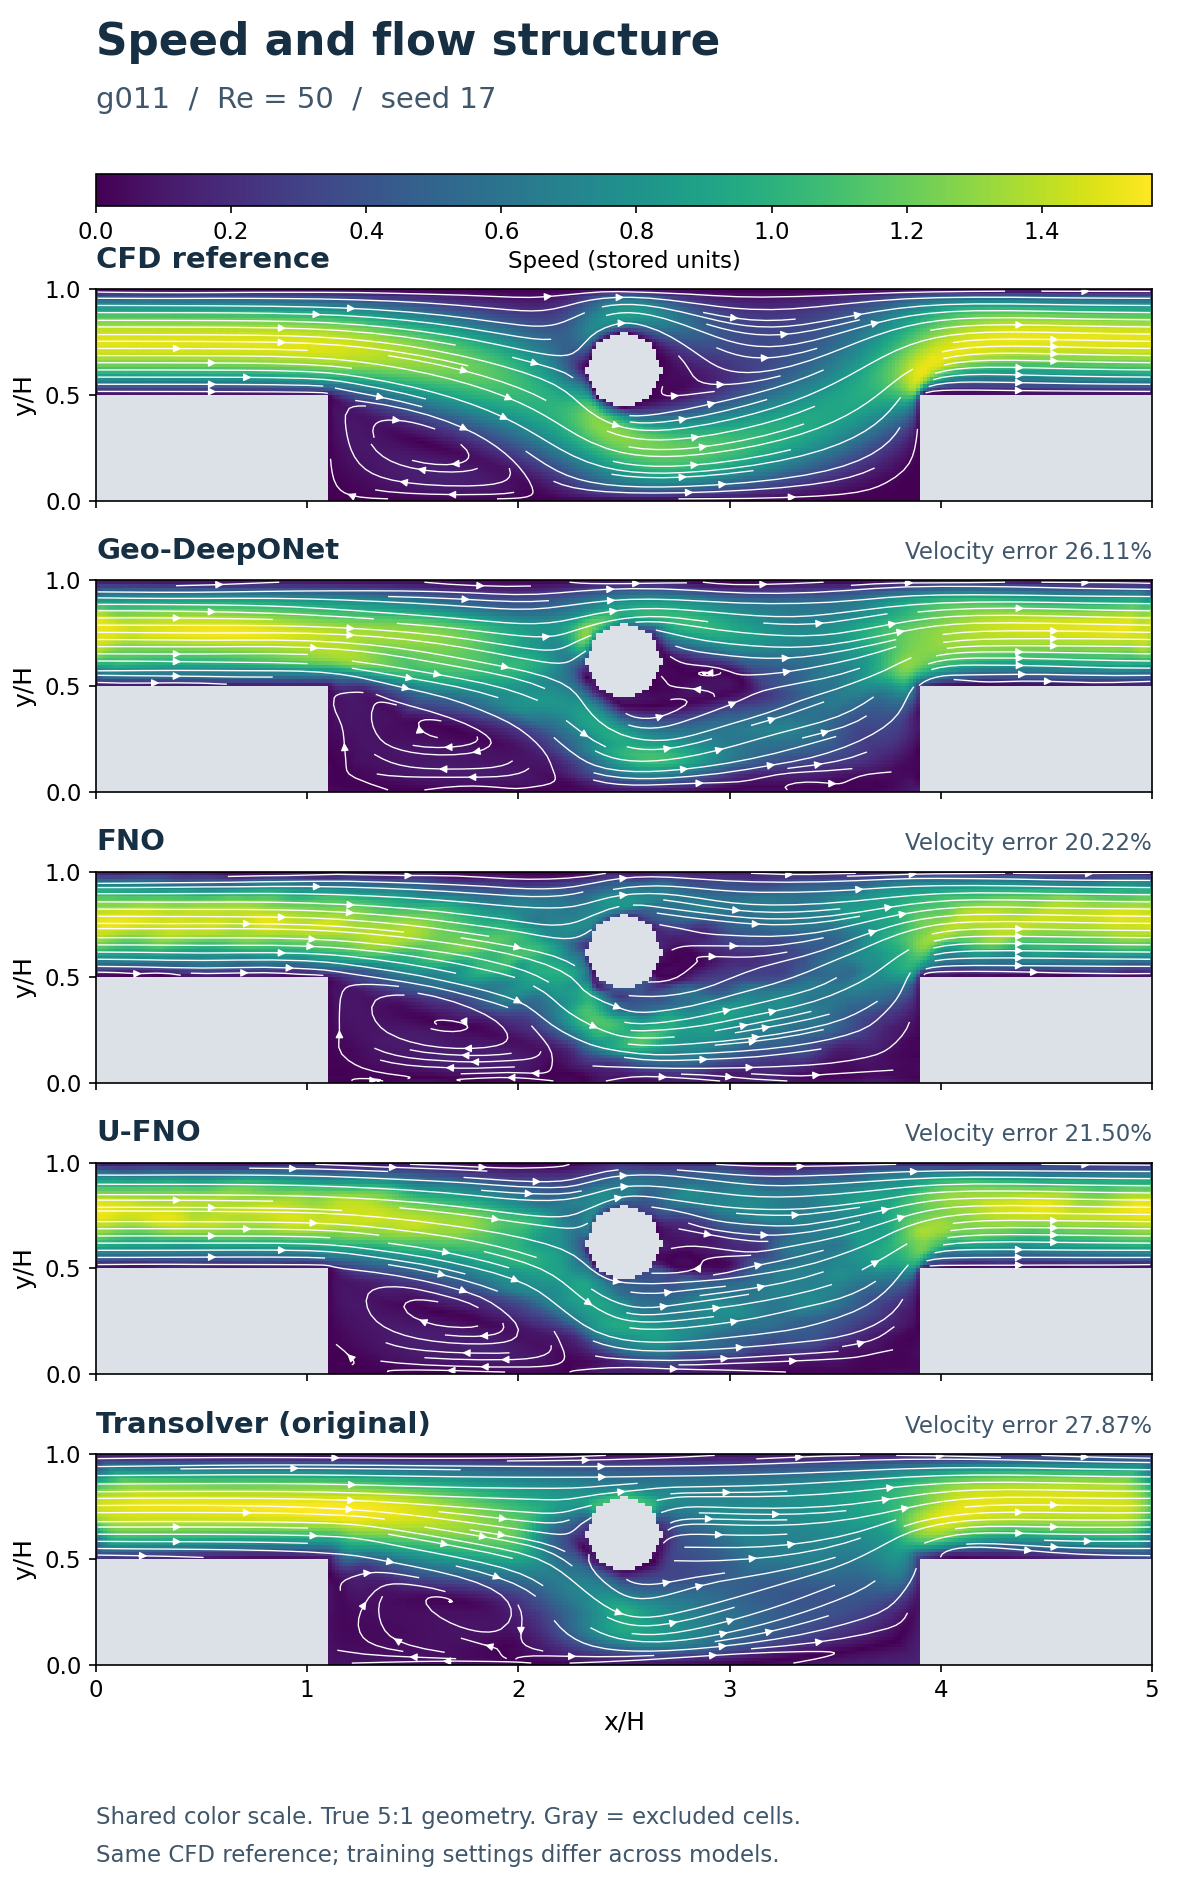

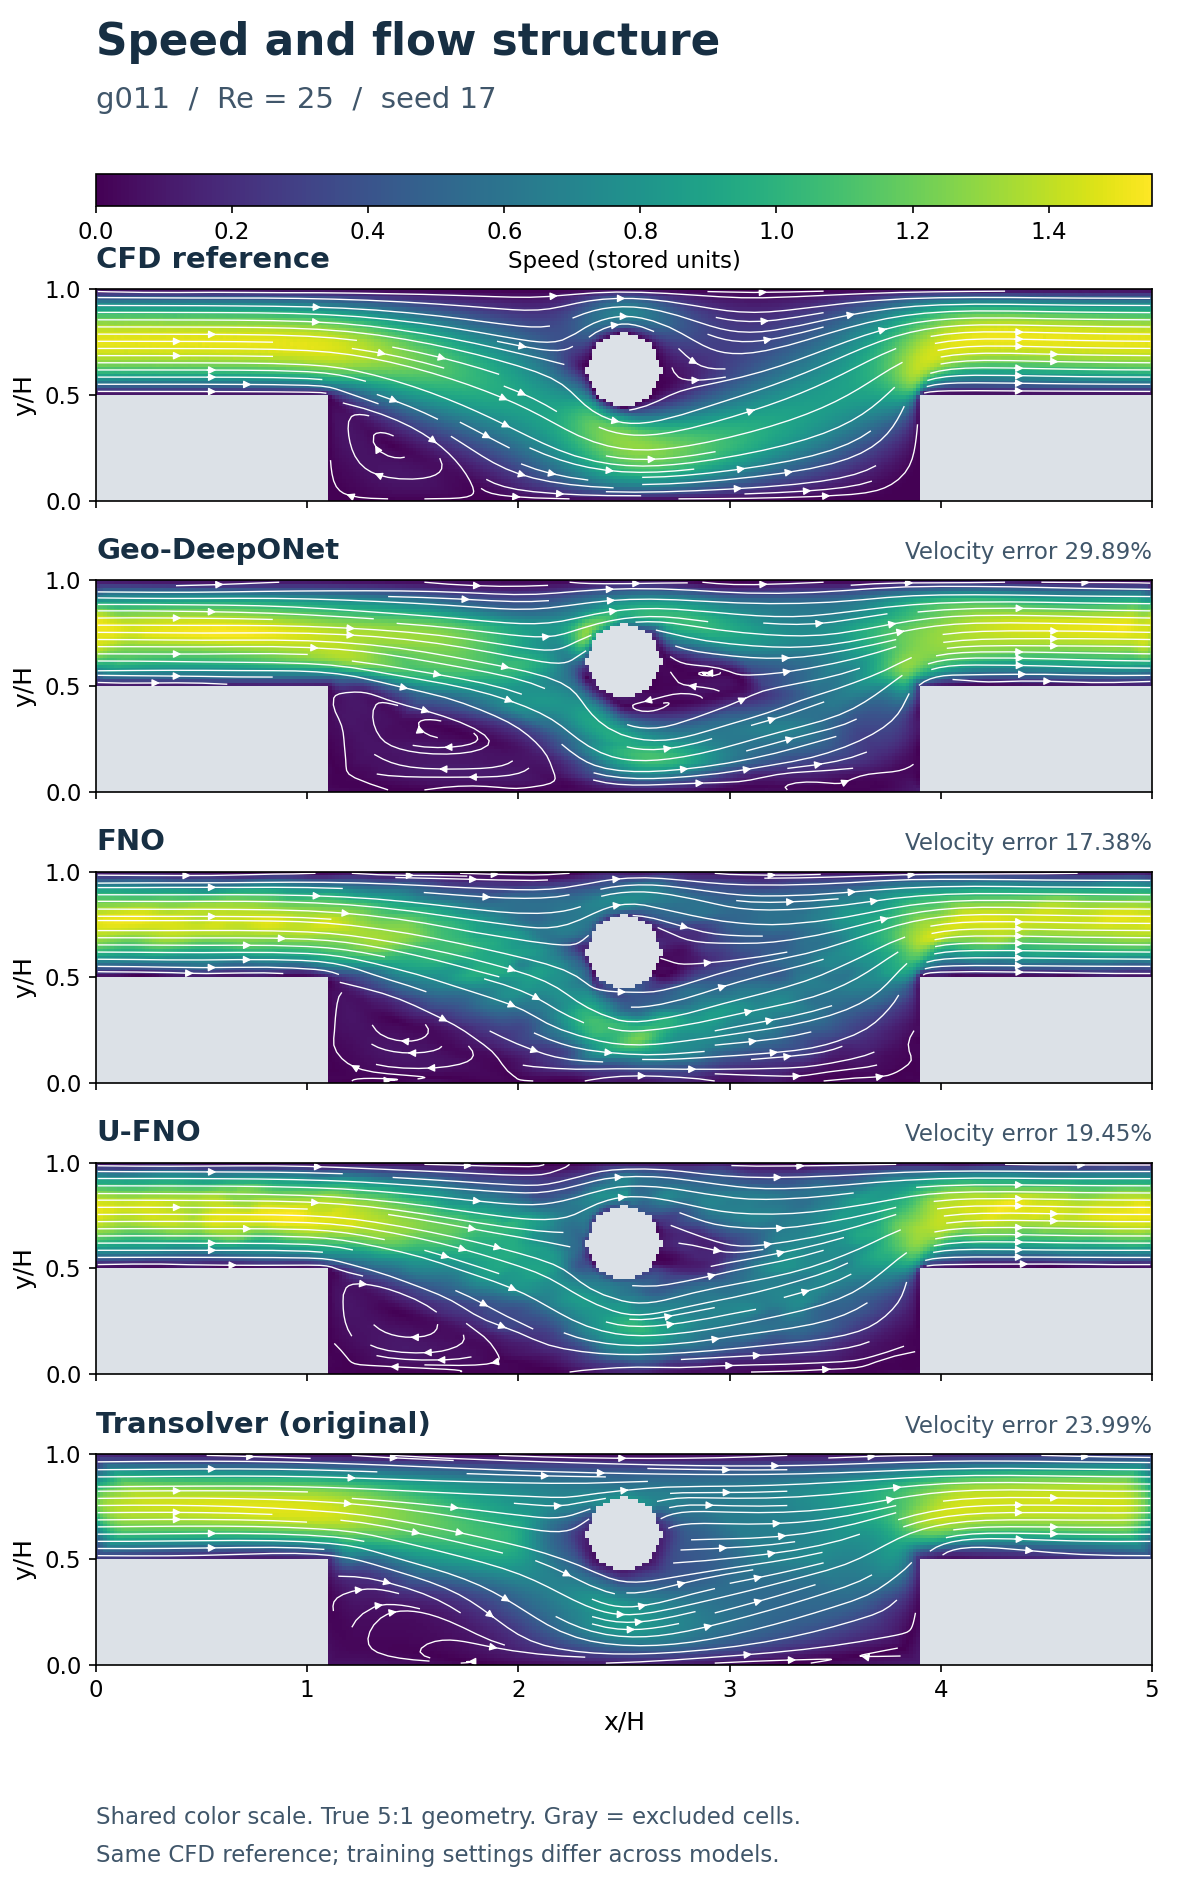

In [3]:
for re in (100,50,25):
    display(Image(filename=str(OUT/f'speed_Re{re}.png')))

### Committed figures (linked rather than duplicated in notebook outputs)

![Re 100 comparison](../../results/step_transolver/all_models_g011_Re100.png)

![Re 50 comparison](../../results/step_transolver/speed_Re50.png)

![Re 25 comparison](../../results/step_transolver/speed_Re25.png)

## What this run establishes

Original Transolver improves mean velocity error relative to the historical
Geo-DeepONet run at Re=25, but worsens it at Re=50/100. Centered-pressure errors
are worse at all three Reynolds numbers. This compact run does **not** support
replacing the existing model as a generally superior predictor.

The full contextual fluid cloud is used at inference; chunking would change
slice aggregation. Geometry-level separation and train-only scaling prevent
label leakage, but this historically inspected geometry is not a fresh blind test.
Training uses uniform fluid sampling and unweighted normalized MSE; historical
models used a different weighted loss. These differences remain visible in the
protocol rather than being presented as a matched optimization study.

Reproduce training with `python qa/train_step_transolver.py --seed 17` (and
29/43). Source, weights, histories, scalers, raw fields and hashes are included. No new CFD is needed.

## Native fields, signs and seed variation

Aim: find where a prediction changes the separated flow, rather than treating a global error as a complete description. The controls below select one **previously inspected retained case**, one physical component and the same three training seeds. They neither select a new checkpoint nor retrain a model.

The first plot fills the CFD field and overlays each seed's prediction at the same physical contour levels. Its companion shows prediction minus CFD with a shared linear signed scale. The second figure compares a native downstream row, with solids masked. Pressure is centered over the same fluid cells for every field before comparison; this removes only the arbitrary constant gauge. A negative streamwise velocity indicates reverse flow, not by itself a complete vortex.

Choose the case before judging the errors. Repeat at Re=25, 50 and 100 where that same geometry exists; preserve all three seeds and report both a gain and a failure.

Retained cases: ['g011_Re100_medium', 'g011_Re25_medium', 'g011_Re50_medium']


,method,relative_l2,signed_error_min,signed_error_max
0,Transolver seed 17,0.263655,-0.630136,1.042457
1,Transolver seed 29,0.285644,-0.739793,0.926440
2,Transolver seed 43,0.270005,-0.685029,0.509831


Native profile row: 0.125 ; no checkpoint replay in this cell.


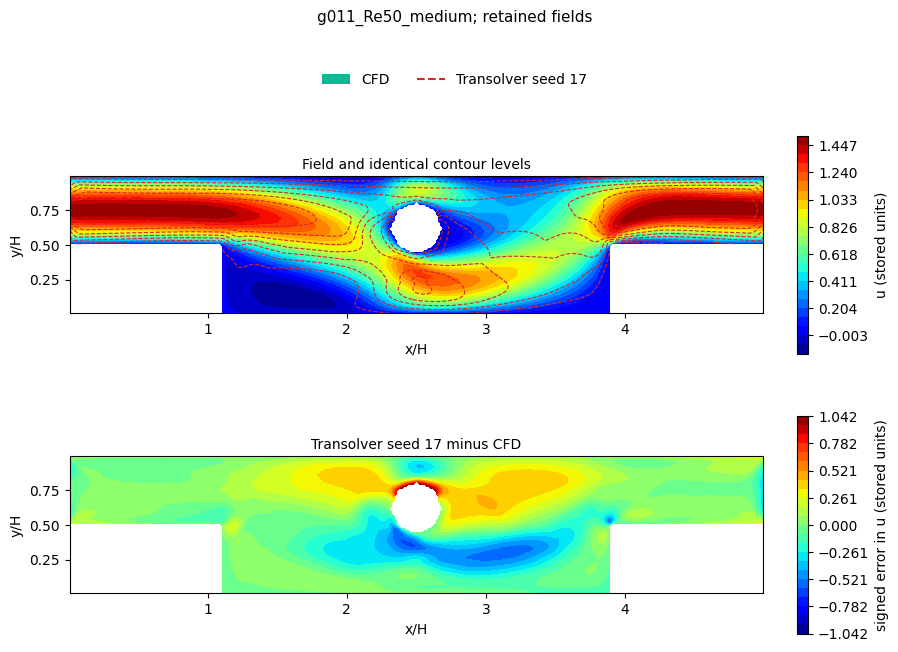

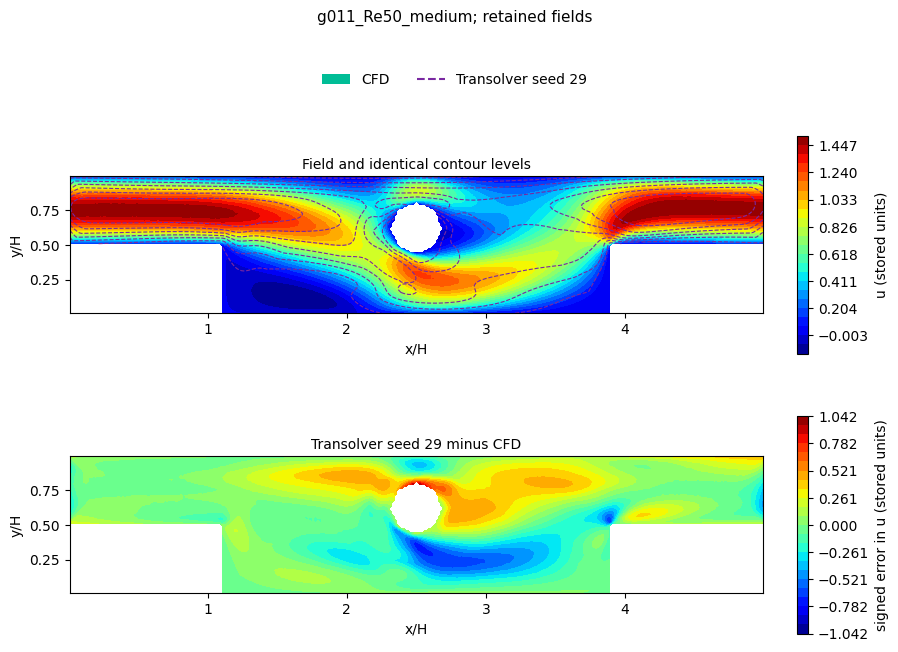

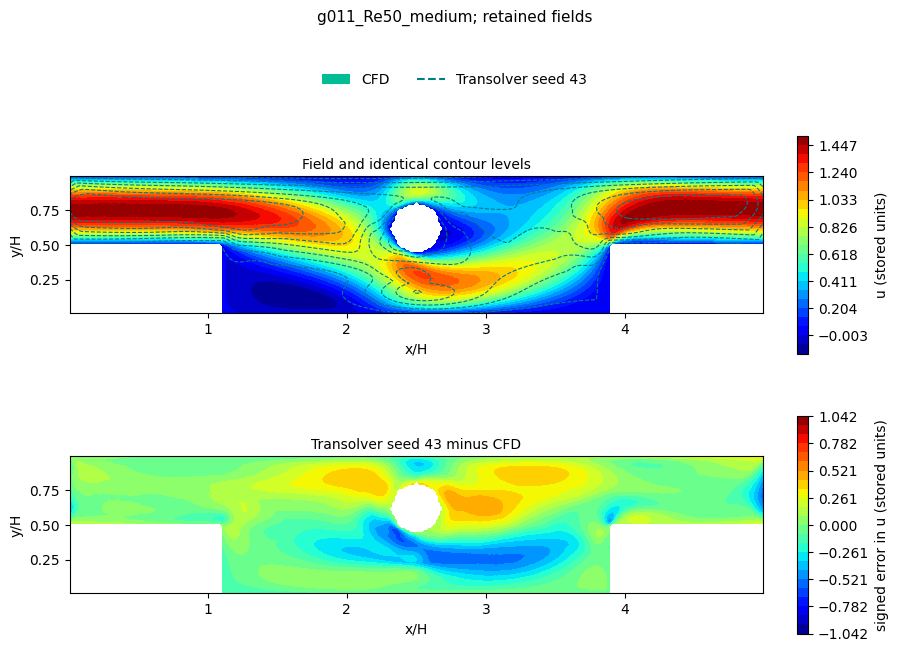

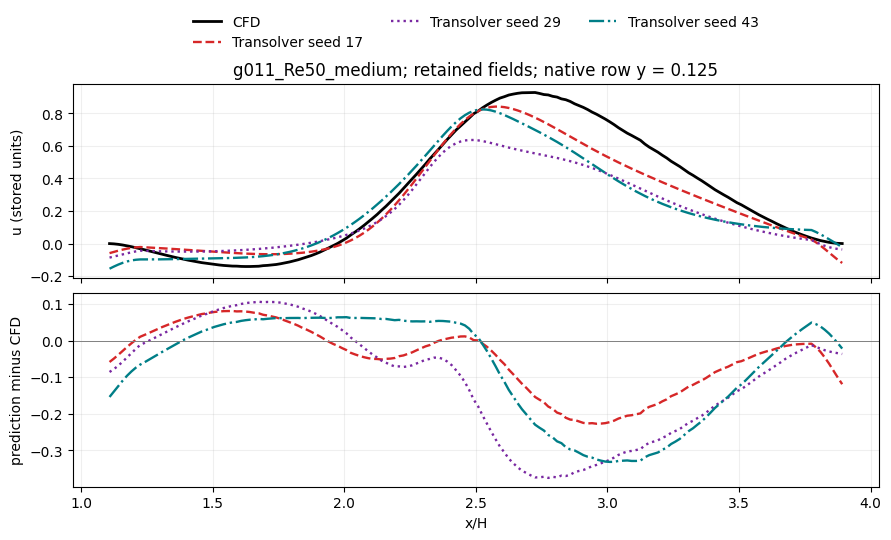

In [4]:
import hashlib
import numpy as np
import matplotlib.pyplot as plt
from flowmllab.late_teaching_plots import field_profiles
CASE = 'g011_Re50_medium'
COMPONENT = "u"  # u, v or pressure; no checkpoint selection
CUT_Y = .12
folder = ROOT / "results/step_transolver"
receipt = json.loads((folder/"verification.json").read_text())
available = sorted({r["case"] for r in receipt["records"]})
print("Retained cases:", available)
if CASE not in available: raise ValueError("Choose a case printed above")
if COMPONENT not in ("u","v","pressure"): raise ValueError("Choose u, v or pressure")
fields=[]
for seed in (17,29,43):
    row=next(r for r in receipt["records"] if r["seed"]==seed and r["case"]==CASE)
    path=folder/f"seed_{seed}"/f"{CASE}_prediction.npz"
    actual=hashlib.sha256(path.read_bytes()).hexdigest()
    if actual!=row["prediction_sha256"]: raise ValueError(f"Changed retained field: {path}")
    with np.load(path,allow_pickle=False) as z: fields.append({k:z[k].copy() for k in z.files})
ref=fields[0]; shape=tuple(map(int,ref["shape"]))
mask=ref["mask"].reshape(shape).astype(bool)
xy=ref["coordinates"].reshape(*shape,2)
channel={"u":0,"v":1,"pressure":2}[COMPONENT]
truth=ref["truth"].reshape(*shape,3)[:,:,channel].astype(float)
predictions={}
for seed,f in zip((17,29,43),fields):
    np.testing.assert_array_equal(f["mask"],ref["mask"])
    np.testing.assert_allclose(f["truth"],ref["truth"],rtol=0,atol=0)
    value=f["prediction"].reshape(*shape,3)[:,:,channel].astype(float)
    if COMPONENT=="pressure":value=value-value[mask].mean()
    predictions[f"Transolver seed {seed}"]=value
if COMPONENT=="pressure":truth=truth-truth[mask].mean()
figures,diagnostics=field_profiles(xy[0,:,0],xy[:,0,1],truth,predictions,
    mask=mask,quantity=f"{COMPONENT} (stored units)",case=f"{CASE}; retained fields",
    cut_y=CUT_Y)
display(pd.DataFrame(diagnostics["metrics"]))
print("Native profile row:",diagnostics["native_profile_y"],"; no checkpoint replay in this cell.")
plt.show()


## A controlled student investigation

1. **Locate a missed feature.** At a fixed geometry/Re and seed, report the native coordinate of the largest signed streamwise-velocity discrepancy, and compare the reverse-flow region with CFD. State whether the main error is strength, location or missing connected regions.
2. **Check repeatability.** Keep that case fixed and compare all three seeds. Report their numerical range, and explain why three runs do not establish a universal architecture ranking.
3. **Change the quantity.** Repeat the same-case comparison for pressure after common fluid-mean centering. Explain why a change in the pressure zero cannot correct the velocity error.
4. **Compare Reynolds regimes.** Use every available Re for the chosen geometry. Submit the matched field/signed-profile figures and a compact table with case, seed, metric definition and native grid. Do not use these retrospective cases to claim a new blind test.

Full checkpoint replay and campaign training are separate research procedures. They require the original dependencies, frozen input/source identities and an isolated output workspace. Default Run All verifies the displayed saved fields and recomputes their diagnostics; it does not rerun those campaigns.